# Laboratorium 4: Transformer jako model

W poprzednich laboratoriach pracowaliśmy z TF-IDF i gotowymi embeddingami. W tym laboratorium przechodzimy do modelu transformerowego używanego bezpośrednio jako klasyfikator.

Śledzimy cały przepływ:

`tekst → tokenizator → input_ids + attention_mask → enkoder → reprezentacja → głowa klasyfikacyjna → logity → predykcja`

Główne pytanie laboratorium brzmi:

**Co daje dostrajanie transformera i kiedy wzrost jakości uzasadnia dodatkowy koszt względem prostszego baseline'u?**

Porównamy:

- `TF-IDF + Linear SVM` z laboratorium 2;
- transformer z zamrożonym enkoderem;
- ten sam transformer po pełnym dostrojeniu.

Laboratorium obejmuje 10 zadań obowiązkowych i jedno opcjonalne.

## Po tych zajęciach student potrafi

- wyjaśnić różnicę między słowem, tokenem i subwordem;
- odczytać `input_ids` i `attention_mask`;
- wyjaśnić rolę paddingu i obcinania sekwencji;
- odczytać podstawowe informacje o architekturze modelu;
- wykonać przejście w przód bez użycia `pipeline()`;
- zinterpretować `last_hidden_state`, logity i wynik softmax;
- przygotować dane do klasyfikacji tekstu transformerem;
- porównać zamrożony enkoder z pełnym dostrajaniem;
- porównać transformera z klasycznym baseline'em;
- porównać model wielojęzyczny z polskim pod względem tokenizacji, jakości i kosztu (opcjonalnie);
- przeprowadzić analizę błędów i uzasadnić decyzję projektową.

## Dane i protokół

Pracujemy na tym samym zbiorze PolEmo 2.0 co w laboratoriach 1-3.

Obowiązuje ten sam protokół:

- `train` -- uczenie;
- `validation` -- porównywanie wariantów i wybór konfiguracji;
- `test` -- jedna końcowa ocena wybranego rozwiązania.

Wynik `TF-IDF + Linear SVM` z laboratorium 2 jest punktem odniesienia. Nie zmieniamy baseline'u po zobaczeniu wyników transformera.

Jeżeli ograniczenia sprzętowe wymagają zmniejszenia liczby przykładów treningowych, należy ustawić TRAIN_LIMIT (np. 2000, próbka stratyfikowana, ta sama we wszystkich eksperymentach transformerowych) i opisać to w karcie modelu.

## Ustawienia wstępne

Wymagane biblioteki:

```bash
pip install pandas numpy matplotlib scikit-learn pyarrow torch transformers datasets accelerate
```

Model używany w laboratorium:

```text
distilbert/distilbert-base-multilingual-cased
```

W Zadaniu 8 (opcjonalnie): `allegro/herbert-base-cased`, model wstępnie wytrenowany na korpusach polskich.


Kod startowy obejmuje importy, stałe i wczytanie danych. Implementacja właściwych eksperymentów należy do Państwa.

In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import re

from datasets import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

from transformers import (
    AutoTokenizer,
    AutoModel,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    set_seed,
)

RANDOM_STATE = 42
set_seed(RANDOM_STATE)

ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)

MODEL_NAME = "distilbert/distilbert-base-multilingual-cased"
# MODEL_PL = "allegro/herbert-base-cased"   # zadanie 8 (opcjonalnie)
MAX_LENGTH = 128        # zadanie 2
TRAIN_LIMIT = None      # None = cały train; na CPU proponowane 2000

DEVICE = (
    "cuda" if torch.cuda.is_available()
    else "mps" if getattr(torch.backends, "mps", None)
    and torch.backends.mps.is_available()
    else "cpu"
)

print("Urządzenie:", DEVICE)

W1123 17:20:47.097000 22248 torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Urządzenie: mps


In [2]:
# helpery z labu 2 (bootstrap_ci, macro_f1) + nowe: paired_bootstrap_diff, token_stats

from sklearn.metrics import f1_score

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")

def bootstrap_ci(y_true, y_pred, metric, n_boot=1000, alpha=0.05, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    n = len(y_true)
    stats = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        stats.append(metric(y_true[i], y_pred[i]))
    lo, hi = np.percentile(stats, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(metric(y_true, y_pred)), float(lo), float(hi)
    
def paired_bootstrap_diff(y_true, pred_a, pred_b, metric, n_boot=1000, alpha=0.05, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y_true, pred_a, pred_b = map(np.asarray, (y_true, pred_a, pred_b))
    n = len(y_true)
    diffs = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        diffs.append(metric(y_true[i], pred_b[i]) - metric(y_true[i], pred_a[i]))
    lo, hi = np.percentile(diffs, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(metric(y_true, pred_b) - metric(y_true, pred_a)), float(lo), float(hi)

def token_stats(tokenizer, texts, max_length):
    texts = list(texts)
    ids = tokenizer(texts, add_special_tokens=True, truncation=False)["input_ids"]
    lens = np.array([len(x) for x in ids])
    n_words = np.array([len(re.findall(r"\w+", t)) for t in texts])
    return {
        "median": float(np.median(lens)),
        "p90": float(np.percentile(lens, 90)),
        "pct_truncated": float((lens > max_length).mean()),
        "tokens_per_word": float(lens.sum() / n_words.sum()),
    }


def inference_ms_per_doc(trainer, dataset=None):
    # sredni czas predykcji na dokument [ms] na zbiorze ewaluacyjnym danego Trainera
    eval_ds = trainer.eval_dataset if dataset is None else dataset
    start = time.perf_counter()
    trainer.predict(eval_ds)
    return (time.perf_counter() - start) / len(eval_ds) * 1000


In [3]:
DATA_PATH = ARTIFACTS / "polemo2_clean.parquet"
assert DATA_PATH.exists(), "Brak artifacts/polemo2_clean.parquet. Proszę wykonać Lab 1."

data = pd.read_parquet(DATA_PATH).dropna(subset=["text", "target"]).reset_index(drop=True)
assert set(data["target"]) == {"plus", "minus", "zero", "amb"}

train_df = data[data["split"] == "train"].reset_index(drop=True)
val_df = data[data["split"].isin(["validation", "valid"])].reset_index(drop=True)
test_df = data[data["split"] == "test"].reset_index(drop=True)

if TRAIN_LIMIT is not None:
    train_df, _ = train_test_split(
        train_df, train_size=TRAIN_LIMIT, stratify=train_df["target"], random_state=RANDOM_STATE
    )
    train_df = train_df.reset_index(drop=True)

CLASSES = sorted(train_df["target"].unique())
print("train:", len(train_df), "validation:", len(val_df), "test:", len(test_df))

train: 5783 validation: 723 test: 722


# Zadanie 1: Audyt tokenizacji

Proszę wczytać tokenizator `MODEL_NAME` i przygotować co najmniej 8 polskich przykładów obejmujących wybrane zróżnicowane zjawiska z podanej poniżej listy:

- częste słowo;
- rzadkie słowo;
- nazwę własną;
- nazwisko;
- wyraz z polskimi znakami;
- ten sam wyraz bez polskich znaków;
- literówkę;
- neologizm;
- emoji;
- URL;
- liczbę;
- termin specjalistyczny.

Dla każdego przykładu proszę zapisać:

| tekst | liczba słów | liczba tokenów | tokeny | obserwacja |
|---|---:|---:|---|---|

Proszę krótko odpowiedzieć:

1. Czy token odpowiada słowu?
2. Jak tokenizator zachowuje się wobec nietypowych form?
3. Dlaczego tokenizacja może wpływać na późniejszy wynik modelu?

In [4]:
# Proszę wczytać tokenizator i przeprowadzić audyt tokenizacji.

mbert_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print("Typ tokenizatora:", type(mbert_tokenizer).__name__)
print("Przykład:", mbert_tokenizer.tokenize("Hotel był bardzo dobry."))

# zestaw zróżnicowanych zjawisk językowych (>= 8 wymaganych kategorii)
audit_examples = [
    ("częste słowo",           "To był bardzo dobry czysty hotel."),
    ("rzadkie słowo",          "Recepcjonistka była przeuroczo rozentuzjazmowana."),
    ("nazwa własna",           "Zatrzymaliśmy się w hotelu Bristol przy Krakowskim Przedmieściu."),
    ("nazwisko",               "Konsjerż pan Niedźwiedzki pomógł nam zorganizować transport na lotnisko."),
    ("polskie znaki",          "W łazience unosił się zapach świeżo wypranych ręczników i żółtych żonkili."),
    ("bez polskich znaków",    "W lazience unosil sie zapach swiezo wypranych recznikow i zoltych zonkili."),
    ("literówka",              "Klimatyzacja w sypialni niestety nie dzaiłała przez całą noc."),
    ("neologizm",              "Zamiast butikowego klimatu zastaliśmy zwykły turystyczny januszex."),
    ("emoji",                  "Widok z tarasu na góry absolutnie obłędny 🏔️✨🥂"),
    ("URL",                    "Pełny cennik i galerię pokojów znajdziecie na https://www.booking.com/hotel/pl/example.html"),
    ("liczba",                 "Za 3 noce ze śniadaniem zapłaciliśmy 1890,99 PLN."),
    ("termin specjalistyczny", "Przez błąd systemu rezerwacyjnego wystąpił klasyczny overbooking."),
]

def describe_tokenization(text):
    pieces = mbert_tokenizer.tokenize(text)
    return pieces, len(text.split()), len(pieces)

audit_records = []
for phenomenon, text in audit_examples:
    pieces, n_words, n_tokens = describe_tokenization(text)
    audit_records.append({
        "zjawisko": phenomenon,
        "tekst": text,
        "liczba słów": n_words,
        "liczba tokenów": n_tokens,
        "tokeny/słowo": round(n_tokens / n_words, 2),
        "tokeny": " | ".join(pieces),
    })

pd.set_option("display.max_colwidth", 180)
token_audit = pd.DataFrame(audit_records)
token_audit


Typ tokenizatora: BertTokenizer
Przykład: ['Hotel', 'był', 'bardzo', 'dob', '##ry', '.']


,zjawisko,tekst,liczba słów,liczba tokenów,tokeny/słowo,tokeny
0,częste słowo,To był bardzo dobry czysty hotel.,6,9,1.50,To | był | bardzo | dob | ##ry | czy | ##sty | hotel | .
1,rzadkie słowo,Recepcjonistka była przeuroczo rozentuzjazmowana.,4,17,4.25,Rec | ##ep | ##c | ##joni | ##stka | była | pr | ##zeu | ##roc | ##zo | ro | ##zent | ##uz | ##ja | ##zm | ##owana | .
2,nazwa własna,Zatrzymaliśmy się w hotelu Bristol przy Krakowskim Przedmieściu.,8,19,2.38,Za | ##tr | ##zym | ##ali | ##ś | ##my | się | w | hotel | ##u | Bristol | przy | Kr | ##ako | ##wskim | Przed | ##mie | ##ściu | .
3,nazwisko,Konsjerż pan Niedźwiedzki pomógł nam zorganizować transport na lotnisko.,9,26,2.89,Ko | ##ns | ##jer | ##ż | pan | Nie | ##d | ##ź | ##wie | ##dz | ##ki | po | ##mó | ##g | ##ł | nam | zo | ##rgan | ##izo | ##wać | transport | na | lot | ##nisk | ##o | .
4,polskie znaki,W łazience unosił się zapach świeżo wypranych ręczników i żółtych żonkili.,11,30,2.73,W | ł | ##azi | ##ence | unos | ##ił | się | za | ##pach | św | ##ie | ##ż | ##o | w | ##y | ##pra | ##nych | r | ##ę | ##cznik | ##ów | i | ż | ##ół | ##tych | ż | ##on | ##ki...
5,bez polskich znaków,W lazience unosil sie zapach swiezo wypranych recznikow i zoltych zonkili.,11,27,2.45,W | la | ##zien | ##ce | unos | ##il | sie | za | ##pach | s | ##wie | ##zo | w | ##y | ##pra | ##nych | re | ##cznik | ##ow | i | zo | ##lty | ##ch | zon | ##kil | ##i | .
6,literówka,Klimatyzacja w sypialni niestety nie dzaiłała przez całą noc.,9,20,2.22,Klima | ##ty | ##zacja | w | sy | ##pia | ##lni | nie | ##ste | ##ty | nie | d | ##zai | ##łał | ##a | przez | całą | no | ##c | .
7,neologizm,Zamiast butikowego klimatu zastaliśmy zwykły turystyczny januszex.,7,22,3.14,Za | ##miast | but | ##iko | ##wego | klima | ##tu | za | ##stal | ##i | ##ś | ##my | z | ##wy | ##k | ##ły | tur | ##ystyczny | jan | ##usz | ##ex | .
8,emoji,Widok z tarasu na góry absolutnie obłędny 🏔️✨🥂,8,13,1.62,Wi | ##dok | z | tar | ##asu | na | góry | absolut | ##nie | ob | ##łę | ##dny | [UNK]
9,URL,Pełny cennik i galerię pokojów znajdziecie na https://www.booking.com/hotel/pl/example.html,8,36,4.50,Pe | ##ł | ##ny | ce | ##nni | ##k | i | gal | ##eri | ##ę | po | ##koj | ##ów | zna | ##jd | ##zie | ##cie | na | https | : | / | / | www | . | book | ##ing | . | com | / | ho...


## Zadanie 1 — wnioski

1. **Czy token odpowiada słowu?** Nie. Tokenizator tnie słowa na subwordy: np. "dobry" -> `dob ##ry`, a w tabeli proporcja `tokeny/słowo` waha się od 1.5 do 4.5. Jeden token to zwykle fragment słowa, nie całe słowo.
2. **Jak zachowuje się wobec nietypowych form?** Rozbija je na wiele kawałków. Dla kategorii: rzadkie słowo, neologizm i url, proporcja `tokeny/słowo` jest największa. To samo zdanie z polskimi znakami (kategoria polskie znaki) ma o 3 tokeny więcej niż to samo bez polskich znaków (kategoria bez polskich znaków). Emoji jest nierozpoznawane przez tokenizator, mamy: `[UNK]`, natomiast liczba 1890.99 jest dzielona na:  `| 1890 | , | 99 |`.
3. **Dlaczego tokenizacja wpływa na wynik?** Model dostaje jako input tokeny. Im więcej tokenów na słowo, tym mniejszy fragment tekstu mieści się w `MAX_LENGTH`, a znaczenie jest rozproszone na wiele subwordów. Dodatkowo te subwordy to mogą być podzielone części słów np litera `ż`. Słaba obsługa polskich znaków i form fleksyjnych na przykład wydłuża sekwencję i utrudnia uczenie modelu. 

# Zadanie 2: `input_ids`, `attention_mask`, padding i obcinanie

Proszę wybrać trzy teksty o różnej długości i przygotować je do wejścia modelu.

Dla każdego tekstu proszę wyświetlić:

- tokeny;
- `input_ids`;
- `attention_mask`;
- długość sekwencji.

Następnie proszę porównać `padding=True` oraz `padding="max_length", max_length=128` i policzyć, jaki procent pozycji w batchu stanowi padding.

Następnie proszę sprawdzić długości tokenowe wszystkich tekstów treningowych i podać:

- medianę;
- percentyl 90;
- percentyl 95;
- maksimum;
- procent tekstów obcinanych przy `MAX_LENGTH=128`.

Na tej podstawie proszę zdecydować, czy `128` jest rozsądną wartością dla dalszej części laboratorium (przy obcinaniu znika koniec tekstu, a w recenzjach często jest tam podsumowanie oceny). Decyzję i procent obciętych tekstów proszę zapisać w karcie modelu.

In [5]:
# Proszę zaimplementować analizę wejścia modelu i długości tokenowych.

train_word_counts = train_df["text"].str.split().str.len()
ranked_by_length = train_word_counts.sort_values()
short_doc = train_df.loc[ranked_by_length.index[1], "text"]
mid_doc   = train_df.loc[ranked_by_length.index[len(ranked_by_length) // 2], "text"]
long_doc  = train_df.loc[ranked_by_length.index[-1], "text"]
sample_docs = {"krótki": short_doc, "średni": mid_doc, "długi": long_doc}

input_rows = []
for length_label, doc in sample_docs.items():
    enc = mbert_tokenizer(doc)
    input_rows.append({
        "długość": length_label,
        "liczba słów": len(doc.split()),
        "liczba tokenów": len(enc["input_ids"]),
        "tokeny": mbert_tokenizer.convert_ids_to_tokens(enc["input_ids"]),
        "input_ids": enc["input_ids"],
        "attention_mask": enc["attention_mask"],
    })
display(pd.DataFrame(input_rows))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1807 > 512). Running this sequence through the model will result in indexing errors


,długość,liczba słów,liczba tokenów,tokeny,input_ids,attention_mask
0,krótki,14,18,"[[CLS], Hotel, ,, jak, za, tą, k, ##wo, ##tę, (, 230, -, 2, osoby, &, aut, o, [SEP]]","[101, 15411, 117, 13050, 10339, 89570, 179, 16828, 46110, 113, 16888, 118, 123, 29375, 111, 49523, 183, 102]","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]"
1,średni,121,211,"[[CLS], Hotel, absolut, ##nie, nie, po, ##win, ##ien, być, 4, -, ro, g, ##wiazd, ##kowym, hotel, ##em, Mer, ##cure, ponieważ, to, bardzo, sz, ##kod, ##zi, marc, ##e, ., Ob, ##s...","[101, 15411, 95230, 11297, 11058, 10514, 24748, 11540, 19669, 125, 118, 25470, 175, 89396, 99503, 19157, 10451, 10734, 55888, 54745, 10114, 24004, 61048, 80852, 11282, 89770, 1...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1..."
2,długi,987,1807,"[[CLS], W, ##y, ##bór, sy, ##l, ##west, ##row, ##ego, pak, ##iet, ##u, w, tym, hotel, ##u, za, gi, ##gant, ##yczne, pieni, ##ąd, ##ze, (, jak, na, za, ##pro, ##pon, ##owane, wa...","[101, 160, 10157, 66781, 12261, 10161, 49458, 21454, 12419, 17284, 20589, 10138, 191, 12644, 19157, 10138, 10339, 38356, 44762, 50533, 73069, 34965, 10870, 113, 13050, 10132, 1...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1..."


In [6]:
batch_docs = list(sample_docs.values())
padding_variants = {
    "padding=True (dynamiczny)":   dict(padding=True),
    "padding='max_length' (128)":  dict(padding="max_length", max_length=MAX_LENGTH),
}
padding_rows = []
for variant_name, kw in padding_variants.items():
    masks = mbert_tokenizer(batch_docs, truncation=True, return_tensors="np", **kw)["attention_mask"]
    padding_rows.append({
        "wariant": variant_name,
        "kształt batcha": tuple(masks.shape),
        "pozycje razem": int(masks.size),
        "pozycje paddingu": int((masks == 0).sum()),
        "udział paddingu [%]": round(float((masks == 0).mean()) * 100, 1),
    })
display(pd.DataFrame(padding_rows))


,wariant,kształt batcha,pozycje razem,pozycje paddingu,udział paddingu [%]
0,padding=True (dynamiczny),"(3, 512)",1536,795,51.8
1,padding='max_length' (128),"(3, 128)",384,110,28.6


In [7]:
all_train_lengths = np.array([
    len(ids) for ids in mbert_tokenizer(train_df["text"].tolist(), add_special_tokens=True, truncation=False)["input_ids"]
])
PCT_TRUNCATED = float((all_train_lengths > MAX_LENGTH).mean() * 100)
length_stats = pd.Series({
    "mediana": float(np.median(all_train_lengths)),
    "p90": float(np.percentile(all_train_lengths, 90)),
    "p95": float(np.percentile(all_train_lengths, 95)),
    "maksimum": int(all_train_lengths.max()),
    f"% obciętych przy MAX_LENGTH={MAX_LENGTH}": round(PCT_TRUNCATED, 2),
}).round(2)
length_stats

mediana                             222.00
p90                                 415.80
p95                                 523.90
maksimum                           1807.00
% obciętych przy MAX_LENGTH=128      84.32
dtype: float64

## Zadanie 2 — padding i decyzja o MAX_LENGTH

- `padding=True` dopasowuje batch do najdłuższego tekstu (tu kształt (3, 512) i **51.8%** pozycji to padding), a `padding="max_length"` zawsze daje (3, 128) i tutej **28.6%** to padding. Dynamiczny padding jest tańszy, bo nie dokłada stałej liczby pustych pozycji w każdym batchu.
- Przy `MAX_LENGTH=128` obcinamy aż **84.32%** recenzji!
> **Decyzja:** zostajemy przy `MAX_LENGTH=128` jako kompromis kosztowy. Padding dynamiczny zwraca 4 razy większe batche i ponad 50% miejsca w batchu to padding. Akceptujemy straty jakościowe i obcinanie prawie 85% recenzji aby zmniejszyć czas treningu i potrzebną pamięć.

# Zadanie 3: Co znajduje się w modelu?

Proszę wczytać bazowy enkoder przez `AutoModel` i odczytać z konfiguracji:

- rozmiar słownika;
- wymiar stanu ukrytego;
- liczbę warstw;
- liczbę głów uwagi;
- maksymalną długość sekwencji.

Następnie proszę samodzielnie policzyć:

- wszystkie parametry modelu;
- parametry trenowalne;
- przybliżony rozmiar samych wag w FP32 i FP16.

Proszę krótko wyjaśnić, dlaczego rzeczywiste zużycie pamięci podczas treningu jest większe niż rozmiar samych wag.


In [8]:
# Proszę wczytać AutoModel, odczytać konfigurację i policzyć parametry oraz przybliżony koszt pamięci wag.

encoder = AutoModel.from_pretrained(MODEL_NAME)
cfg = encoder.config

architecture_info = pd.DataFrame([
    ("rozmiar słownika",                   cfg.vocab_size),
    ("wymiar stanu ukrytego",              cfg.hidden_size),
    ("liczba warstw",                      cfg.num_hidden_layers),
    ("liczba głów uwagi",                  cfg.num_attention_heads),
    ("maks. długość sekwencji (config)",   cfg.max_position_embeddings),
    ("maks. długość sekwencji (tokenizer)", mbert_tokenizer.model_max_length),
], columns=["parametr", "wartość"])
display(architecture_info)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert/distilbert-base-multilingual-cased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,parametr,wartość
0,rozmiar słownika,119547
1,wymiar stanu ukrytego,768
2,liczba warstw,6
3,liczba głów uwagi,12
4,maks. długość sekwencji (config),512
5,maks. długość sekwencji (tokenizer),512


In [9]:
total_params = sum(p.numel() for p in encoder.parameters())
trainable_params = sum(p.numel() for p in encoder.parameters() if p.requires_grad)

weight_budget = pd.DataFrame([
    ("parametry łącznie",    f"{total_params:,}"),
    ("parametry trenowalne", f"{trainable_params:,}"),
    ("wagi w FP32 [MB]",     f"{total_params * 4 / 1024**2:.1f}"),
    ("wagi w FP16 [MB]",     f"{total_params * 2 / 1024**2:.1f}"),
], columns=["pozycja", "wartość"])
weight_budget

,pozycja,wartość
0,parametry łącznie,"134,734,080"
1,parametry trenowalne,"134,734,080"
2,wagi w FP32 [MB],514.0
3,wagi w FP16 [MB],257.0


## Zadanie 3 — pamięć podczas treningu

Enkoder ma ok. **134.7 mln** parametrów; same jego wagi zajmują **514 MB** w FP32. Rzeczywiste zużycie pamięci w treningu jest jednak znacznie większe, bo poza wagami trzeba przechowywać: gradient — po jednym na każdy parametr (kolejne ~514 MB), stany optymalizatora i aktywacje - z przejścia w przód, potrzebne do wstecznej propagacji (rosną z batch size i długością sekwencji).

Dlatego trening zajmuje **kilkukrotność rozmiaru samych wag** w pamieci, a **nie tylko 514 MB**.

# Zadanie 4: Ręczne przejście w przód

Proszę wybrać jeden tekst i wykonać `tekst → tokenizator → tensory → AutoModel → last_hidden_state` bez użycia `pipeline()`.

Należy:

1. podać kształty tensorów wejściowych;
2. podać kształt `last_hidden_state`;
3. wyjaśnić znaczenie każdego wymiaru;
4. przypisać tokeny do odpowiadających im reprezentacji;
5. utworzyć jeden wektor dokumentu przez mean pooling z uwzględnieniem `attention_mask`.

Następnie proszę wczytać `AutoModelForSequenceClassification`, wykonać pojedynczą predykcję przed treningiem i:

- odczytać logity;
- zastosować softmax;
- sprawdzić, czy wartości po softmax sumują się do 1.

Proszę pamiętać, że wynik softmax nie jest automatycznie skalibrowaną miarą pewności modelu.

Na końcu proszę wyjaśnić, dlaczego predykcja z losowo zainicjalizowaną głową klasyfikacyjną nie ma jeszcze sensownej jakości.


In [10]:
# Proszę wykonać ręczne przejście w przód, mean pooling oraz analizę logitów i wyniku softmax.

# jeden tekst o umiarkowanej-dużej długości
probe_counts = train_df["text"].str.split().str.len()
probe_idx = (probe_counts - 175).abs().sort_values().index[0]
probe_text = train_df.loc[probe_idx, "text"]
print("Analizowany tekst:", probe_text[:220], "...\n")

Analizowany tekst: chodziła m do pana doktora na wizyty podczas ciąży . niestety nie zlecał regularnie badań krwi i moczu . mówił , że nie trzeba robić badań co miesiąc . sama je robiła m na własną rękę jak zwrócił mi na to uwagę lekarz w  ...



In [11]:
# 1. tekst -> tokenizator -> tensory
encoded = mbert_tokenizer(probe_text, return_tensors="pt", truncation=True, max_length=MAX_LENGTH)
print("kształty wejścia:", {name: tuple(t.shape) for name, t in encoded.items()})

# 2. tensory -> AutoModel -> last_hidden_state
encoder.eval()
with torch.no_grad():
    encoder_out = encoder(**encoded)
hidden_states = encoder_out.last_hidden_state
print("kształt last_hidden_state:", tuple(hidden_states.shape))

# 3-4. przypisanie tokenów do reprezentacji
probe_tokens = mbert_tokenizer.convert_ids_to_tokens(encoded["input_ids"][0])
token_to_vector = pd.DataFrame({
    "pozycja": range(len(probe_tokens)),
    "token": probe_tokens,
    "wektor[:3]": [hidden_states[0, i, :3].numpy().round(3) for i in range(len(probe_tokens))],
})
display(token_to_vector.head(10))

# 5. mean pooling z uwzględnieniem attention_mask
mask_f = encoded["attention_mask"].unsqueeze(-1).float()
doc_embedding = (hidden_states * mask_f).sum(dim=1) / mask_f.sum(dim=1)
print("wektor dokumentu (mean pooling):", tuple(doc_embedding.shape))


kształty wejścia: {'input_ids': (1, 128), 'token_type_ids': (1, 128), 'attention_mask': (1, 128)}
kształt last_hidden_state: (1, 128, 768)


,pozycja,token,wektor[:3]
0,0,[CLS],"[0.139, -0.062, 0.008]"
1,1,cho,"[-0.347, -0.213, 0.425]"
2,2,##dził,"[0.362, -0.344, 0.668]"
3,3,##a,"[0.248, -0.065, 1.416]"
4,4,m,"[0.171, -0.237, 0.144]"
5,5,do,"[0.097, -0.471, 0.338]"
6,6,pan,"[-0.58, -0.331, -0.073]"
7,7,##a,"[0.233, -0.652, 1.379]"
8,8,doktora,"[-0.071, -0.529, 0.474]"
9,9,na,"[0.241, -0.35, 0.262]"


wektor dokumentu (mean pooling): (1, 768)


In [12]:
pretrain_classifier = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=len(CLASSES))
pretrain_classifier.eval()
with torch.no_grad():
    raw_logits = pretrain_classifier(**encoded).logits
softmax_probs = torch.softmax(raw_logits, dim=1)
print("logity:", raw_logits.numpy().round(4))
print("softmax:", softmax_probs.numpy().round(4))
print("suma po softmax:", float(softmax_probs.sum()))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


logity: [[-0.0211 -0.0381 -0.0057  0.0935]]
softmax: [[0.2427 0.2386 0.2465 0.2722]]
suma po softmax: 1.0


## Zadanie 4 — kształty, softmax i losowa głowa

- **Kształty:** `input_ids`/`attention_mask` to (1, 128); `last_hidden_state` to **(1, 128, 768)** = (batch, liczba tokenów, wymiar ukryty). Każdemu z 128 tokenów odpowiada wektor 768-wymiarowy.
- **Mean pooling** z maską uśrednia tylko realne tokeny (pomija padding) i daje jeden wektor dokumentu (1, 768).
- **Softmax** zamienia logity na rozkład prawdopodobieństwa — wartości sumują się do **1.0**. Po zastosowaniu softmax na logitach widzimy, że rozkład jest prawie jednostajny (`[0.2427 0.2386 0.2465 0.2722]`) czyli ok. 0.25 na każdą z czterech klas.
- **Dlaczego predykcja przed treningiem nie ma sensu?** Głowa klasyfikacyjna (`pre_classifier`, `classifier`) jest **losowo zainicjalizowana**. Enkoder zna język, jest przetrenowany ale głowa nie widziała jeszcze żadnej etykiety, więc logity są bliskie zeru, a softmax bliski losowemu zgadywaniu. Wyniki do sensownej intepretacji pojawią się dopiero po fine-tuningu.

Uwaga do zadań 3-4: Nazwy pól w konfiguracji DistilBERT różnią się od BERT-a (`dim`, `n_layers`, `n_heads`), ale działają też aliasy (`hidden_size`, `num_hidden_layers`, `num_attention_heads`).

Przy ładowaniu `AutoModelForSequenceClassification` pojawi się ostrzeżenie o nowo zainicjalizowanych wagach. Proszę wyjaśnić, które to wagi i dlaczego jest to oczekiwane.

Którą pozycję z `last_hidden_state` wykorzystuje głowa klasyfikacyjna tego modelu i czym różni się to od mean poolingu?

## Odpowiedzi do uwag (Zad. 3-4)

- **Które wagi są nowe?** Nowo inicjalizowane są warstwy głowy: `pre_classifier.weight/bias` (warstwa 768 -> 768) oraz `classifier.weight/bias` (warstwa 768 -> 4 klasy). W raporcie oznaczone jako `MISSING`. To oczekiwane — checkpoint bazowy był trenowany jako model językowy, więc nie zawiera głowy do 4-klasowej klasyfikacji sentymentu. W raporcie widzimy też etykietę `UNEXPECTED` przy elementach: `vocab_*`, które są niepotrzebne do klasyfikacji. Oba ostrzeżenia sa spodziewane.
- **Którą pozycję wykorzystuje głowa?** `DistilBertForSequenceClassification` przekazuje do głowy reprezentację **pierwszego tokenu `[CLS]`** (`last_hidden_state[:, 0]`), przepuszczając ją kolejno przez `pre_classifier`  oraz `classifier`. Wektor `[CLS]` pełni rolę pojedynczej pozycji agregującej kontekst całej sekwencji, która dopiero w trakcie fine-tuningu na naszych danych uczy się zbierać informacje istotne dla klasyfikacji. Dla porównania **mean pooling** uśrednia wektory wszystkich realnych tokenów, traktując je równorzędnie — dzięki temu daje sensowną reprezentację całego tekstu „od ręki” bez trenowania dedykowanej głowy, podczas gdy głowa klasyfikacyjna polega na jednej, wyspecjalizowanej podczas fine-tuningu pozycji.

# Zadanie 5: Przygotowanie klasyfikatora

Proszę przygotować pełny pipeline treningowy dla klasyfikacji PolEmo 2.0.

Należy samodzielnie:

1. przygotować mapowania `label2id` i `id2label`;
2. utworzyć obiekty `Dataset` dla `train` i `validation`;
3. napisać funkcję tokenizującą batch;
4. użyć dynamicznego `DataCollatorWithPadding`;
5. zaimplementować `compute_metrics`;
6. przygotować `TrainingArguments`;
7. utworzyć `Trainer`.

Główną metryką jest `macro-F1`.

Konfiguracja domyślna (zmiana tylko z uzasadnieniem): 3 epoki, batch size 16, `weight_decay=0.01`, `warmup_ratio=0.1`, `MAX_LENGTH` z Zadania 2.

Proszę ustawić `report_to="none"` i `save_strategy="no"` (domyślnie `Trainer` zapisuje checkpointy po ok. 0,5 GB). Nazwy argumentów `TrainingArguments` i `Trainer` zmieniały się między wersjami `transformers` (m.in. `evaluation_strategy` → `eval_strategy`, `tokenizer` → `processing_class`), więc proszę zapisać `import transformers`.

Proszę zapisać użyte `MAX_LENGTH`, batch size, learning rate, liczbę epok, seed i urządzenie.

In [13]:
# Proszę przygotować dane i pipeline treningowy.
import math

BATCH_SIZE = 16
NUM_EPOCHS = 3
FINETUNE_LR = 5e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1

label2id = {label: idx for idx, label in enumerate(CLASSES)}
id2label = {idx: label for label, idx in label2id.items()}

def tokenize_batch(batch, tokenizer):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

def build_dataset(frame, tokenizer):
    ds = Dataset.from_dict({
        "text": frame["text"].tolist(),
        "labels": frame["target"].map(label2id).tolist(),
    })
    return ds.map(lambda b: tokenize_batch(b, tokenizer), batched=True, remove_columns=["text"])

def compute_metrics(eval_pred):
    logits, gold = eval_pred
    preds = logits.argmax(axis=-1)
    return {"macro_f1": macro_f1(gold, preds), "accuracy": accuracy_score(gold, preds)}

def build_classifier(checkpoint):
    return AutoModelForSequenceClassification.from_pretrained(
        checkpoint, num_labels=len(CLASSES), id2label=id2label, label2id=label2id, attn_implementation="eager",
    )

def warmup_from_ratio(n_examples, epochs=NUM_EPOCHS, batch_size=BATCH_SIZE, ratio=WARMUP_RATIO):
    return int(ratio * math.ceil(n_examples / batch_size) * epochs)

def build_trainer(model, learning_rate, train_ds, eval_ds, tokenizer, *, eval_each_epoch=True, warmup_steps=None):
    args = TrainingArguments(
        output_dir="trainer_output",
        num_train_epochs=NUM_EPOCHS,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE,
        learning_rate=learning_rate,
        weight_decay=WEIGHT_DECAY,
        warmup_steps=warmup_from_ratio(len(train_ds)) if warmup_steps is None else warmup_steps,
        eval_strategy="epoch" if eval_each_epoch else "no",
        save_strategy="no",
        report_to="none",
        seed=RANDOM_STATE,
        logging_steps=50,
        dataloader_pin_memory=False,
    )
    return Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        processing_class=tokenizer,
        data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
        compute_metrics=compute_metrics,
    )

import transformers
print("wersja transformers:", transformers.__version__)

distil_train_ds = build_dataset(train_df, mbert_tokenizer)
distil_val_ds = build_dataset(val_df, mbert_tokenizer)

print(f"MAX_LENGTH={MAX_LENGTH}, batch={BATCH_SIZE}, lr(fine-tune)={FINETUNE_LR}, epochs={NUM_EPOCHS}, seed={RANDOM_STATE}, device={DEVICE}")

wersja transformers: 5.22.2


Map:   0%|          | 0/5783 [00:00<?, ? examples/s]

Map:   0%|          | 0/723 [00:00<?, ? examples/s]

MAX_LENGTH=128, batch=16, lr(fine-tune)=5e-05, epochs=3, seed=42, device=mps


# Zadanie 6: Zamrożony enkoder

Proszę załadować model klasyfikacyjny i zamrozić cały enkoder (`model.base_model`). Trenowana ma być wyłącznie głowa klasyfikacyjna (w DistilBERT: `pre_classifier` i `classifier`).

Learning rate dla tego wariantu proszę dobrać osobno (typowo ok. `1e-3`; wartość rzędu `2e-5` prawie nie uczy samej głowy w trzech epokach). Liczba epok i pozostałe warunki są takie same jak w zadaniu 5.

Proszę:

1. policzyć liczbę wszystkich parametrów;
2. policzyć liczbę parametrów trenowalnych;
3. podać procent parametrów trenowalnych;
4. wytrenować model;
5. zmierzyć czas treningu;
6. obliczyć accuracy i macro-F1 na zbiorze walidacyjnym.

Przed treningiem proszę zapisać hipotezę dotyczącą oczekiwanej jakości tego wariantu.

> Hipoteza: Wariant z **zamrożonym enkoderem** będzie wyraźnie słabszy od pełnego dostrajania i prawdopodobnie nie pobije baseline'u TF-IDF + SVM bo trenujemy małą ilosc parametrów tylko głowy klasyfikacyjnej.

In [ ]:
print("transformers:", transformers.__version__)
print("transformers path:", transformers.__file__)

print("accelerate:", accelerate.__version__)
print("accelerate path:", accelerate.__file__)

print("metadata:", importlib.metadata.version("accelerate"))
print("is_accelerate_available:", is_accelerate_available())

transformers: 5.22.2
transformers path: /Users/joannaheldak/venvs/.notebooks_DS_common/lib/python3.12/site-packages/transformers/__init__.py
accelerate: 1.16.0
accelerate path: /Users/joannaheldak/venvs/.notebooks_DS_common/lib/python3.12/site-packages/accelerate/__init__.py
metadata: 1.16.0
is_accelerate_available: True


In [16]:
# Proszę zaimplementować wariant z zamrożonym enkoderem.

FROZEN_LR = 1e-3  # wyższy LR

frozen_clf = build_classifier(MODEL_NAME)
for param in frozen_clf.base_model.parameters():
    param.requires_grad = False

frozen_total = sum(p.numel() for p in frozen_clf.parameters())
frozen_trainable = sum(p.numel() for p in frozen_clf.parameters() if p.requires_grad)
print(f"parametry łącznie: {frozen_total:,}")
print(f"parametry trenowalne: {frozen_trainable:,} ({frozen_trainable / frozen_total:.2%})")

frozen_trainer = build_trainer(frozen_clf, FROZEN_LR, distil_train_ds, distil_val_ds, mbert_tokenizer)

t0 = time.perf_counter()
frozen_trainer.train()
frozen_train_s = time.perf_counter() - t0

frozen_eval = frozen_trainer.predict(distil_val_ds)
frozen_val_pred = frozen_eval.predictions.argmax(axis=1)
val_gold = frozen_eval.label_ids
frozen_acc = accuracy_score(val_gold, frozen_val_pred)
frozen_f1 = macro_f1(val_gold, frozen_val_pred)
print(f"czas treningu: {frozen_train_s:.1f} s | val accuracy: {frozen_acc:.3f} | val macro-F1: {frozen_f1:.3f}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


parametry łącznie: 135,327,748
parametry trenowalne: 593,668 (0.44%)


Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,1.043496,0.924826,0.546645,0.654219
2,0.919502,0.907807,0.476144,0.536653
3,0.888539,0.802009,0.600405,0.683264


czas treningu: 62.9 s | val accuracy: 0.683 | val macro-F1: 0.600


## Zadanie 6 — weryfikacja hipotezy

Hipoteza się potwierdziła. Zamrożony enkoder osiągnął **F1 0.600** (accuracy 0.683), trenując jedynie **593 668** parametrów (**0.44%** wszystkich parametrów) w **62.9 s**. Metryka jest wyraźnie poniżej baseline'u TF-IDF + SVM (ok. 0.8) — sama głowa nad niedostrojonymi reprezentacjami `[CLS]` nie wystarcza do tego zadania.

# Zadanie 7: Pełne dostrajanie i porównanie na walidacji

Proszę załadować świeżą kopię tego samego checkpointu i przeprowadzić pełne dostrajanie modelu.

Warunki: ten sam podział danych, to samo `MAX_LENGTH`, ten sam sposób ewaluacji i ta sama liczba epok co w Zadaniu 5. Learning rate dobieramy osobno do wariantu (pełne dostrajanie: typowo `2e-5`–`5e-5`).

Dla wariantu dostrojonego proszę zmierzyć: liczbę parametrów trenowalnych, czas treningu, accuracy, macro-F1 i średni czas inferencji na dokument (ta sama maszyna, podany batch size).

| model | trainable params | train_s | ms/doc | accuracy | macro-F1 | macro-F1 CI95 |
|---|---:|---:|---:|---:|---:|---:|
| TF-IDF + Linear SVM | -- | | | | | |
| frozen transformer | | | | | | |
| fine-tuned transformer | | | | | | |

Przedział ufności liczymy funkcją `bootstrap_ci` z Lab 2. Predykcje walidacyjne obu transformerów proszę zapisać (będą potrzebne w Zadaniach 8 i 10).

Opcjonalnie: proszę powtórzyć dostrajanie dla drugiego seeda. Dostrajanie ma wyraźną wariancję między seedami, więc różnic rzędu kilku dziesiątych punktu macro-F1 nie należy traktować jako przewagi.

In [ ]:
# Proszę przeprowadzić pełne dostrajanie, zapisać predykcje walidacyjne i uzupełnić tabelę.
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline

# pełne dostrajanie DistilBERT - świeży checkpoint
finetuned_clf = build_classifier(MODEL_NAME)
finetuned_trainer = build_trainer(finetuned_clf, FINETUNE_LR, distil_train_ds, distil_val_ds, mbert_tokenizer)

finetuned_total = sum(p.numel() for p in finetuned_clf.parameters())
finetuned_trainable = sum(p.numel() for p in finetuned_clf.parameters() if p.requires_grad)
print(f"parametry trenowalne (fine-tune): {finetuned_trainable:,} ({finetuned_trainable / finetuned_total:.2%})")

t0 = time.perf_counter()
finetuned_trainer.train()
finetuned_train_s = time.perf_counter() - t0

finetuned_eval = finetuned_trainer.predict(distil_val_ds)
finetuned_val_pred = finetuned_eval.predictions.argmax(axis=1)
finetuned_ms_doc = inference_ms_per_doc(finetuned_trainer, distil_val_ds)
print(f"czas treningu: {finetuned_train_s:.1f} s | ms/doc: {finetuned_ms_doc:.1f}")

# baseline z Lab 2: TF-IDF + Linear SVM
svm_baseline = Pipeline([
    ("tfidf", TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, max_features=50_000, sublinear_tf=True)),
    ("svm", LinearSVC(random_state=RANDOM_STATE)),
])
train_label_ids = train_df["target"].map(label2id).to_numpy()
t0 = time.perf_counter()
svm_baseline.fit(train_df["text"], train_label_ids)
svm_train_s = time.perf_counter() - t0
t0 = time.perf_counter()
svm_val_pred = svm_baseline.predict(val_df["text"])
svm_ms_doc = (time.perf_counter() - t0) / len(val_df) * 1000

frozen_ms_doc = inference_ms_per_doc(frozen_trainer, distil_val_ds)

def val_result_row(name, trainable, train_s, ms_doc, preds):
    f1, lo, hi = bootstrap_ci(val_gold, preds, metric=macro_f1)
    return {
        "model": name,
        "trainable params": trainable,
        "train_s": round(train_s, 1),
        "ms/doc": round(ms_doc, 2),
        "accuracy": round(accuracy_score(val_gold, preds), 3),
        "macro-F1": round(f1, 3),
        "macro-F1 CI95": f"{lo:.3f}–{hi:.3f}",
    }

validation_comparison = pd.DataFrame([
    val_result_row("TF-IDF + Linear SVM",     "—",                       svm_train_s,       svm_ms_doc,      svm_val_pred),
    val_result_row("frozen transformer",      f"{frozen_trainable:,}",   frozen_train_s,    frozen_ms_doc,   frozen_val_pred),
    val_result_row("fine-tuned transformer",  f"{finetuned_trainable:,}", finetuned_train_s, finetuned_ms_doc, finetuned_val_pred),
])
validation_comparison


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


parametry trenowalne (fine-tune): 135,327,748 (100.00%)


Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,0.743064,0.610367,0.719872,0.756570
2,0.501156,0.561069,0.761984,0.792531
3,0.293326,0.623156,0.774947,0.793914


czas treningu: 183.7 s | ms/doc: 2.8


,model,trainable params,train_s,ms/doc,accuracy,macro-F1,macro-F1 CI95
0,TF-IDF + Linear SVM,—,1.2,0.07,0.822,0.788,0.758–0.817
1,frozen transformer,"593,668",62.9,2.95,0.683,0.600,0.571–0.629
2,fine-tuned transformer,"135,327,748",183.7,2.84,0.794,0.775,0.746–0.803


## Zadanie 7 — porównanie na walidacji

Dla wariantu pełnego dostrajania wszystkich parametrów, metryka F1 mocno skacze nam w górę. Dla zamrożonego enkodera było 0.600, dla pełnego dostrajania dostajemy 0.775. Czas trenowania jest ok. 3 razy dłuższy. Uważam, że jest to bardzo duża poprawa wyniku względem nie tak dużego wzrostu czasu treningu. Czasy inferencji są bardzo podobne, bo architektua nie zmienia się między mdoelami.
Niestety nawet dostrojony DistilBERT nie bije baseline'u SVM (0.788) według metryki F1, aczkolwiek przedziały ufności (0.758-0.817 dla TF-IDF + Linear SVM oraz 0.746-0.803 dla fine-tuned transformer) się nakładają, więc to praktycznie remis — a SVM jest ok. 150 razy szybszy w treningu i  ok. 40 razy szybszy w inferencji (0.07 sla SVM i 2.84 ms/dok dla fine-tuned tranformer).

- Wniosek: sam duży, wielojęzyczny transformer nie gwarantuje przewagi nad mocnym klasykiem.

# (opcjonalnie) Zadanie 8: Model polski czy wielojęzyczny?

Dotychczas używaliśmy `distilbert-base-multilingual-cased` (6 warstw, słownik wielojęzyczny). Sprawdzimy, czy model wstępnie wytrenowany na polskich korpusach, `allegro/herbert-base-cased` (BERT, 12 warstw, słownik 50 tys. tokenów), daje przewagę i za jaką cenę.

## Część A: tokenizacja (bez treningu)

Proszę wczytać oba tokenizatory (HerBERT: `AutoTokenizer.from_pretrained(MODEL_PL)`) i dla 500 losowych dokumentów z `train_df` policzyć funkcją `token_stats`: medianę i p90 liczby tokenów, procent tekstów obciętych przy `MAX_LENGTH` oraz liczbę tokenów na słowo.

Następnie proszę porównać podział przykładów z Zadania 1 (także form z odciętą końcówką osobową, np. `Był em`, `miała m`) i zapisać, które słowa dzielą się inaczej.

## Część B: dostrajanie

Proszę dostroić HerBERT-a w tych samych warunkach co dostrojony DistilBERT z Zadania 7: te same `MAX_LENGTH`, liczba epok, batch size, seed i próbka danych, learning rate z tego samego przedziału. Przy ładowaniu `AutoModelForSequenceClassification` pojawi się ostrzeżenie o nowo zainicjalizowanych wagach. Proszę zapisać, które warstwy są nowe.

## Część C: porównanie

Proszę rozszerzyć tabelę z Zadania 7 o wiersz `fine-tuned HerBERT` (trainable params, train_s, ms/doc, accuracy, macro-F1, CI95) oraz policzyć różnicę macro-F1 (HerBERT − DistilBERT) z przedziałem ufności funkcją `paired_bootstrap_diff` na tych samych przykładach walidacyjnych.

Pytania:

1. Który model ma więcej parametrów, a który jest wolniejszy? Dlaczego liczba parametrów nie wystarcza do oszacowania kosztu obliczeń?
2. Czy różnica jakości jest istotna w świetle przedziału ufności?
3. Czy tokenizatory inaczej dzielą polskie formy (Część A)? Czy na podstawie tego eksperymentu można stwierdzić, że to wyjaśnia różnicę jakości?

In [22]:
# Część A: porównanie tokenizatorów (token_stats)
# Część B: dostrojenie HerBERT-a (zapisać predykcje walidacyjne)
# Część C: tabela i paired_bootstrap_diff

MODEL_PL = "allegro/herbert-base-cased" 

# A
herbert_tokenizer = AutoTokenizer.from_pretrained(MODEL_PL)
tok_sample = train_df["text"].sample(n=min(500, len(train_df)), random_state=RANDOM_STATE).tolist()

tokenizer_stats = pd.DataFrame(
    [token_stats(mbert_tokenizer, tok_sample, MAX_LENGTH), token_stats(herbert_tokenizer, tok_sample, MAX_LENGTH)],
    index=["DistilBERT multilingual", "HerBERT"],
)
tokenizer_stats["pct_truncated"] = tokenizer_stats["pct_truncated"] * 100
display(tokenizer_stats.round(2))

person_ending_examples = [
    ("odcięta końcówka osobowa", "Był em tam wczoraj ."),
    ("odcięta końcówka osobowa", "Pani doktor była miła , ale miała m wątpliwości ."),
]
split_rows = []
for phenomenon, text in audit_examples + person_ending_examples:
    distil_pieces = mbert_tokenizer.tokenize(text)
    herbert_pieces = herbert_tokenizer.tokenize(text)
    split_rows.append({
        "zjawisko": phenomenon,
        "tekst": text,
        "DistilBERT: l. tokenów": len(distil_pieces),
        "HerBERT: l. tokenów": len(herbert_pieces),
        "Δ (Distil−Her)": len(distil_pieces) - len(herbert_pieces),
        "DistilBERT": " | ".join(distil_pieces),
        "HerBERT": " | ".join(herbert_pieces),
    })
display(pd.DataFrame(split_rows))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (519 > 512). Running this sequence through the model will result in indexing errors


,median,p90,pct_truncated,tokens_per_word
DistilBERT multilingual,215.0,412.3,84.4,2.17
HerBERT,146.0,283.1,59.4,1.47


,zjawisko,tekst,DistilBERT: l. tokenów,HerBERT: l. tokenów,Δ (Distil−Her),DistilBERT,HerBERT
0,częste słowo,To był bardzo dobry czysty hotel.,9,7,2,To | był | bardzo | dob | ##ry | czy | ##sty | hotel | .,To</w> | był</w> | bardzo</w> | dobry</w> | czysty</w> | hotel</w> | .</w>
1,rzadkie słowo,Recepcjonistka była przeuroczo rozentuzjazmowana.,17,13,4,Rec | ##ep | ##c | ##joni | ##stka | była | pr | ##zeu | ##roc | ##zo | ro | ##zent | ##uz | ##ja | ##zm | ##owana | .,Re | cep | cjoni | stka</w> | była</w> | prze | uro | czo</w> | roz | entuzjaz | m | owana</w> | .</w>
2,nazwa własna,Zatrzymaliśmy się w hotelu Bristol przy Krakowskim Przedmieściu.,19,13,6,Za | ##tr | ##zym | ##ali | ##ś | ##my | się | w | hotel | ##u | Bristol | przy | Kr | ##ako | ##wskim | Przed | ##mie | ##ściu | .,Zatrzy | maliśmy</w> | się</w> | w</w> | hotelu</w> | Bri | sto | l</w> | przy</w> | Krakowskim</w> | Przed | mieściu</w> | .</w>
3,nazwisko,Konsjerż pan Niedźwiedzki pomógł nam zorganizować transport na lotnisko.,26,14,12,Ko | ##ns | ##jer | ##ż | pan | Nie | ##d | ##ź | ##wie | ##dz | ##ki | po | ##mó | ##g | ##ł | nam | zo | ##rgan | ##izo | ##wać | transport | na | lot | ##nisk | ##o | .,Kon | s | jer | ż</w> | pan</w> | Niedźwie | dzki</w> | pomógł</w> | nam</w> | zorganizować</w> | transport</w> | na</w> | lotnisko</w> | .</w>
4,polskie znaki,W łazience unosił się zapach świeżo wypranych ręczników i żółtych żonkili.,30,18,12,W | ł | ##azi | ##ence | unos | ##ił | się | za | ##pach | św | ##ie | ##ż | ##o | w | ##y | ##pra | ##nych | r | ##ę | ##cznik | ##ów | i | ż | ##ół | ##tych | ż | ##on | ##kil | ##i | .,W</w> | łazience</w> | u | nosił</w> | się</w> | zapach</w> | świeżo</w> | wy | pra | nych</w> | ręcz | ników</w> | i</w> | żółtych</w> | żon | ki | li</w> | .</w>
5,bez polskich znaków,W lazience unosil sie zapach swiezo wypranych recznikow i zoltych zonkili.,27,27,0,W | la | ##zien | ##ce | unos | ##il | sie | za | ##pach | s | ##wie | ##zo | w | ##y | ##pra | ##nych | re | ##cznik | ##ow | i | zo | ##lty | ##ch | zon | ##kil | ##i | .,W</w> | la | zie | nce</w> | u | nosi | l</w> | sie</w> | zapach</w> | s | wie | zo</w> | wy | pra | nych</w> | re | czni | kow</w> | i</w> | zo | l | tych</w> | z | on | ki | li</w> | .</w>
6,literówka,Klimatyzacja w sypialni niestety nie dzaiłała przez całą noc.,20,16,4,Klima | ##ty | ##zacja | w | sy | ##pia | ##lni | nie | ##ste | ##ty | nie | d | ##zai | ##łał | ##a | przez | całą | no | ##c | .,Kli | maty | zacja</w> | w</w> | sypialni</w> | niestety</w> | nie</w> | dz | a | i | ł | ała</w> | przez</w> | całą</w> | noc</w> | .</w>
7,neologizm,Zamiast butikowego klimatu zastaliśmy zwykły turystyczny januszex.,22,14,8,Za | ##miast | but | ##iko | ##wego | klima | ##tu | za | ##stal | ##i | ##ś | ##my | z | ##wy | ##k | ##ły | tur | ##ystyczny | jan | ##usz | ##ex | .,Zamiast</w> | bu | ti | kowego</w> | klimatu</w> | zasta | liśmy</w> | zwykły</w> | turystyczny</w> | jan | u | sze | x</w> | .</w>
8,emoji,Widok z tarasu na góry absolutnie obłędny 🏔️✨🥂,13,14,-1,Wi | ##dok | z | tar | ##asu | na | góry | absolut | ##nie | ob | ##łę | ##dny | [UNK],Widok</w> | z</w> | tara | su</w> | na</w> | góry</w> | absolutnie</w> | ob | łęd | ny</w> | <unk> | <unk> | <unk> | <unk>
9,URL,Pełny cennik i galerię pokojów znajdziecie na https://www.booking.com/hotel/pl/example.html,36,33,3,Pe | ##ł | ##ny | ce | ##nni | ##k | i | gal | ##eri | ##ę | po | ##koj | ##ów | zna | ##jd | ##zie | ##cie | na | https | : | / | / | www | . | book | ##ing | . | com | / | hotel | / | pl | / | e...,Peł | ny</w> | cen | nik</w> | i</w> | galerię</w> | poko | jów</w> | znaj | dziecie</w> | na</w> | htt | ps</w> | :</w> | /</w> | /</w> | www</w> | .</w> | bo | ok | ing</w> | .</w> | com</w> | /...


## Część A - Komentarz
HerBERT jest znacznie oszczędniejszy na polskim: mediana **146** tokenów vs **215** u DistilBERT, **1.47** vs **2.17** tokenów/słowo, a przy `MAX_LENGTH=128` obcina **59.4%** tekstów zamiast **84.4%**. W przykładach widzimy, że HerBERT rozdziela polskie słowa w mniej kawałków. Szczególnie duża różnica w ilości tokenów jest dla kategorii:  nazwisko, polskie znaki, neologizm np.: 
- nazwisko:  Nie | ##d | ##ź | ##wie | ##dz | ##ki --> Niedźwie | dzki
- ł | ##azi | ##ence  --> łazience</w>

HerBERT oszczędniej dzieli końcówki osobowe np.: Za | ##tr | ##zym | ##ali | ##ś | ##my --> Zatrzy | maliśmy</w>

Oba tokenizatory nie rozpoznają emoji i zwracają `unk`.
> Wniosek: HerBERT jest znacznie bardziej dopasowany do polszczyzny. Skoro jesteśmy ograniczeni przez długość sekwencji `MAX_LENGTH=128`, wtedy ten model zobaczy większą część recenzji a pojedyncze tokeny będą niosły większy kontekst niż podzielone słowo praktycznie litera po literce.

In [23]:
# B
herbert_train_ds = build_dataset(train_df, herbert_tokenizer)
herbert_val_ds = build_dataset(val_df, herbert_tokenizer)

herbert_clf = build_classifier(MODEL_PL)
herbert_trainer = build_trainer(herbert_clf, FINETUNE_LR, herbert_train_ds, herbert_val_ds, herbert_tokenizer)

herbert_total = sum(p.numel() for p in herbert_clf.parameters())
herbert_trainable = sum(p.numel() for p in herbert_clf.parameters() if p.requires_grad)
print(f"HerBERT parametry: {herbert_total:,} (trenowalne {herbert_trainable:,})")

t0 = time.perf_counter()
herbert_trainer.train()
herbert_train_s = time.perf_counter() - t0

herbert_eval = herbert_trainer.predict(herbert_val_ds)
herbert_val_pred = herbert_eval.predictions.argmax(axis=1)
herbert_ms_doc = inference_ms_per_doc(herbert_trainer, herbert_val_ds)


Map:   0%|          | 0/5783 [00:00<?, ? examples/s]

Map:   0%|          | 0/723 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: allegro/herbert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.sso.sso_relationship.bias              | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.sso.sso_relationship.weight            | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those param

HerBERT parametry: 124,445,956 (trenowalne 124,445,956)


Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,0.405532,0.326191,0.853693,0.875519
2,0.258252,0.420784,0.840706,0.867220
3,0.148284,0.521582,0.856820,0.874136


## Część B - Komentarz
Przy ładowaniu HerBERT-a nowe są tylko `classifier.weight/bias` czyli głowa klasyfikacyjna 768 -> 4 klasy; pozostałe wagi to pretrenowany BERT. Głowa z pretreningu (`cls.*`) jest odrzucana jako UNEXPECTED.

W przeciwieństwie do DistiBERT, herBERT  ma wytrenowany pooler (przetwarzający wektor [CLS]), stąd nowa jest tylko jedna warstwa ( nie ma `classifier`).


In [24]:
# C
herbert_comparison = pd.concat([
    validation_comparison,
    pd.DataFrame([val_result_row("fine-tuned HerBERT", f"{herbert_trainable:,}", herbert_train_s, herbert_ms_doc, herbert_val_pred)]),
], ignore_index=True)
display(herbert_comparison)

diff_f1, diff_lo, diff_hi = paired_bootstrap_diff(val_gold, finetuned_val_pred, herbert_val_pred, metric=macro_f1)
print(f"Δ macro-F1 (HerBERT − DistilBERT): {diff_f1:+.3f} (95% CI: {diff_lo:+.3f} … {diff_hi:+.3f})")
print(f"parametry: HerBERT {herbert_total/1e6:.1f} mln vs DistilBERT {finetuned_total/1e6:.1f} mln")
print(f"trening {herbert_train_s/finetuned_train_s:.1f}× dłuższy, inferencja {herbert_ms_doc/finetuned_ms_doc:.1f}× wolniejsza")


,model,trainable params,train_s,ms/doc,accuracy,macro-F1,macro-F1 CI95
0,TF-IDF + Linear SVM,—,1.2,0.07,0.822,0.788,0.758–0.817
1,frozen transformer,"593,668",62.9,2.95,0.683,0.600,0.571–0.629
2,fine-tuned transformer,"135,327,748",183.7,2.84,0.794,0.775,0.746–0.803
3,fine-tuned HerBERT,"124,445,956",334.1,5.50,0.874,0.857,0.831–0.882


Δ macro-F1 (HerBERT − DistilBERT): +0.082 (95% CI: +0.048 … +0.119)
parametry: HerBERT 124.4 mln vs DistilBERT 135.3 mln
trening 1.8× dłuższy, inferencja 1.9× wolniejsza


## Część C — Komentarz
1. Który model ma więcej parametrów, a który jest wolniejszy? Dlaczego liczba parametrów nie wystarcza do oszacowania kosztu obliczeń?

DistilBERT ma *więcej* parametrów (**ok. 135.3 mln**) niż HerBERT (**124 mln** — słownik 50 tys. zamiast 120 tys.), ale HerBERT jest **wolniejszy**. Trening zajmuje ok. 1.8 razy dłużej, inferencja jest ok. 2 razy dłuższa  (5.75 vs 2.84 ms/dok), bo ma 12 warstw zamiast 6. Liczba parametrów nie oddaje kosztu obliczeń — decyduje liczba operacji na token (głębokość).

2. Czy różnica jakości jest istotna w świetle przedziału ufności?

Tak. Δ macro-F1 (HerBERT − DistilBERT): +0.082 95% CI od +0.048 do +0.119. Przedział nie zawiera zera, więc przewaga HerBERTA nie jest losowa. HerBERT nie tylko przebuja DistilBERTa ale również znacząco przebija baseline TF-IDF + Linear SVM.

3. Czy tokenizatory inaczej dzielą polskie formy (Część A)? Czy na podstawie tego eksperymentu można stwierdzić, że to wyjaśnia różnicę jakości?

Tokenizatory faktycznie inaczej dzielą polskie formy (Część A). HerBERT dzieli polskie słowa, szczególnie odmiany osobowe, nazwiska, nazwy własne na mniejszą ilość tokenów od DistilBERTa. Ale ten eksperyment nie *dowodzi*, że z teog powodu obserwujemy różnicę jakości pomiedzy zastosowaniem obu tokenizatorów. W obutokenizatorach różni się też korpus pretreningu (polski vs 100 języków) i liczba warstw (12 vs 6). To korelacja, nie dowód przyczynowy.

# Zadanie 9*: Wybór finalisty i ostateczny test

Na podstawie wyłącznie wyników walidacyjnych (Zadania 6-8) proszę wybrać jeden wariant do końcowej oceny. Jeśli różnica między kandydatami mieści się w przedziale ufności, proszę to zaznaczyć i uzasadnić wybór kosztem.

Następnie:

1. proszę połączyć `train + validation`;
2. wytrenować wybrany wariant od początku (te same hiperparametry i liczba epok);
3. wykonać jedną ocenę na zbiorze testowym.

Proszę zapisać accuracy, macro-F1, F1 dla każdej klasy, macierz pomyłek i czas inferencji, a wynik porównać z wynikiem testowym `TF-IDF + Linear SVM` z Lab 2 (ten sam zbiór testowy).

Po obejrzeniu wyniku testowego konfiguracja nie może być już zmieniana.

Uwaga: model finalny widział `validation`, więc analiza błędów (zadanie 10) dotyczy modelu wytrenowanego wyłącznie na `train`.

macro-F1 na walidacji: {'fine-tuned DistilBERT': 0.775, 'fine-tuned HerBERT': 0.848}
Finalista: fine-tuned HerBERT (val macro-F1 0.848)


Map:   0%|          | 0/6506 [00:00<?, ? examples/s]

Map:   0%|          | 0/722 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: allegro/herbert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.sso.sso_relationship.bias              | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.sso.sso_relationship.weight            | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those param

Step,Training Loss
50,1.323157
100,0.774864
150,0.489474
200,0.537182
250,0.487790
300,0.430365
350,0.415560
400,0.409172
450,0.312631
500,0.291443


TEST accuracy: 0.878
TEST macro-F1: 0.860 (95% CI: 0.831–0.884) | 5.65 ms/doc
              precision    recall  f1-score   support

         amb      0.660     0.630     0.645       108
       minus      0.891     0.903     0.897       300
        plus      0.904     0.909     0.906       197
        zero      0.991     0.991     0.991       117

    accuracy                          0.878       722
   macro avg      0.862     0.858     0.860       722
weighted avg      0.876     0.878     0.877       722



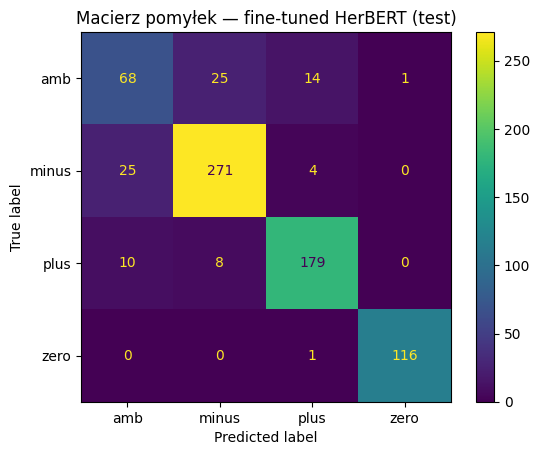

TF-IDF + Linear SVM (test) macro-F1: 0.792 (95% CI: 0.760–0.824)
Δ macro-F1 (finalista − SVM): +0.068 (95% CI: +0.032 … +0.102)


In [ ]:
# Proszę wybrać finalistę na validation i wykonać jednorazowy finalny test.
import math
from sklearn.base import clone
from sklearn.metrics import confusion_matrix

val_candidates = {
    "fine-tuned DistilBERT": (MODEL_NAME, mbert_tokenizer, macro_f1(val_gold, finetuned_val_pred)),
    "fine-tuned HerBERT":    (MODEL_PL,   herbert_tokenizer, macro_f1(val_gold, herbert_val_pred)),
}
finalist_name = max(val_candidates, key=lambda k: val_candidates[k][2])
finalist_checkpoint, finalist_tokenizer, finalist_val_f1 = val_candidates[finalist_name]
print("macro-F1 na walidacji:", {k: round(v[2], 3) for k, v in val_candidates.items()})
print(f"Finalista: {finalist_name} (val macro-F1 {finalist_val_f1:.3f})")

final_train_df = pd.concat([train_df, val_df], ignore_index=True)
final_train_ds = build_dataset(final_train_df, finalist_tokenizer)
test_ds = build_dataset(test_df, finalist_tokenizer)

final_model = build_classifier(finalist_checkpoint)
final_trainer = build_trainer(
    final_model, FINETUNE_LR, final_train_ds, test_ds, finalist_tokenizer,
    eval_each_epoch=False, warmup_steps=warmup_from_ratio(len(final_train_df)),
)
t0 = time.perf_counter()
final_trainer.train()
final_train_s = time.perf_counter() - t0

t0 = time.perf_counter()
final_eval = final_trainer.predict(test_ds)
final_ms_doc = (time.perf_counter() - t0) / len(test_ds) * 1000
test_pred = final_eval.predictions.argmax(axis=1)
test_gold = final_eval.label_ids

test_f1, test_lo, test_hi = bootstrap_ci(test_gold, test_pred, metric=macro_f1)
print(f"TEST accuracy: {accuracy_score(test_gold, test_pred):.3f}")
print(f"TEST macro-F1: {test_f1:.3f} (95% CI: {test_lo:.3f}–{test_hi:.3f}) | {final_ms_doc:.2f} ms/doc")
print(classification_report(test_gold, test_pred, target_names=CLASSES, digits=3))
ConfusionMatrixDisplay(confusion_matrix(test_gold, test_pred), display_labels=CLASSES).plot()
plt.title(f"Macierz pomyłek — {finalist_name} (test)")
plt.show()

svm_final = clone(svm_baseline).fit(final_train_df["text"], final_train_df["target"].map(label2id))
svm_test_pred = svm_final.predict(test_df["text"])
svm_test_f1, svm_test_lo, svm_test_hi = bootstrap_ci(test_gold, svm_test_pred, metric=macro_f1)
diff_ft, diff_ft_lo, diff_ft_hi = paired_bootstrap_diff(test_gold, svm_test_pred, test_pred, metric=macro_f1)
print(f"TF-IDF + Linear SVM (test) macro-F1: {svm_test_f1:.3f} (95% CI: {svm_test_lo:.3f}–{svm_test_hi:.3f})")
print(f"Δ macro-F1 (finalista − SVM): {diff_ft:+.3f} (95% CI: {diff_ft_lo:+.3f} … {diff_ft_hi:+.3f})")


## Zadanie 9 — finalista i test

**Wybór (wyłącznie na walidacji):** finalistą jest **fine-tuned HerBERT** — najwyższe macro-F1. Wyższe od DistilBERTa i od Baseline'u. Akceptowalny koszt tutaj to wolniejsza inferencja.

**Wynik testowy** (trening na train+val): accuracy **0.878**, macro-F1 **0.860 (95% CI: 0.831–0.884)**, inferencja **5.65 ms/doc**. Najtrudniejsza jest klasa `amb`(tego się spodziewamy, tak wychodziło też w poprzednich laboratoriach). Baseline TF-IDF + SVM na tym samym teście: macro-F1 **0.792 (95% CI: 0.760–0.824)**. 

**Wynik F1 dla poszczególnych klas**: amb: 0.645, minus: 0.897, plus: 0.906 , zero: 0.991 

Różnica **finalista − SVM = +0.068 (95% CI: +0.032 … +0.102)** — przedział nie obejmuje zera, więc przewaga polskiego transformera nad baseline'em jest tutaj istotna (inaczej niż dla wielojęzycznego DistilBERT na walidacji).

# Zadanie 10*: Analiza błędnych predykcji

Dla najlepszego transformera wytrenowanego wyłącznie na `train` (nie dla modelu finalnego z zadania 9) proszę wybrać dokładnie 12 błędnych predykcji ze zbioru walidacyjnego (wylosowanych z `random_state=RANDOM_STATE`).

Każdy przypadek proszę przypisać do krótkiej kategorii, np. `AMBIGUOUS_GOLD`, `MIXED_SENTIMENT`, `NEGATION`, `IRONY_SARCASM`, `LONG_CONTEXT`, `VERY_SHORT`, `LEXICAL_TRAP`, `TRUNCATION`, `NON_REVIEW`, `PRETOKENIZATION`, `OTHER`.

Tabela powinna zawierać:

| nr | tekst | gold | predykcja | typ błędu | komentarz |
|---:|---|---|---|---|---|

Proszę dodatkowo zaznaczyć, jeśli w labie stworzyli Państwo takie check, czy TF-IDF + Linear SVM (predykcje z labu 2) popełnił ten sam błąd.

Nie należy jeszcze proponować rozwiązania każdego pojedynczego błędu. Najpierw proszę wskazać powtarzające się wzorce.

In [29]:
# Proszę przygotować analizę dokładnie 12 błędnych predykcji.

best_val_pred, best_tokenizer = herbert_val_pred, herbert_tokenizer
val_token_lengths = np.array([
    len(ids) for ids in herbert_tokenizer(val_df["text"].tolist(), truncation=False)["input_ids"]
])

error_frame = pd.DataFrame({
    "tekst": val_df["text"].values,
    "gold": [id2label[i] for i in val_gold],
    "predykcja": [id2label[i] for i in best_val_pred],
    "SVM": [id2label[i] for i in svm_val_pred],
    "n_tokens": val_token_lengths,
})
error_frame["obcięty"] = error_frame["n_tokens"] > MAX_LENGTH
error_frame["SVM ten sam błąd"] = (error_frame["SVM"] != error_frame["gold"]) & (error_frame["SVM"] == error_frame["predykcja"])

misclassified = error_frame[error_frame["gold"] != error_frame["predykcja"]]
twelve_errors = misclassified.sample(n=12, random_state=RANDOM_STATE).copy()

print("Rozkład wstępnych typów błędów:")
print(f"\nTen sam błąd co SVM: {int(twelve_errors['SVM ten sam błąd'].sum())}/12")
print(f"Teksty obcięte (> {MAX_LENGTH} tokenów): {int(twelve_errors['obcięty'].sum())}/12")
with pd.option_context("display.max_colwidth", None):
    display(twelve_errors)

Rozkład wstępnych typów błędów:

Ten sam błąd co SVM: 7/12
Teksty obcięte (> 128 tokenów): 6/12


,tekst,gold,predykcja,SVM,n_tokens,obcięty,SVM ten sam błąd
371,"Atutem tego hotelu jest położenie . Leży w centrum miasta , tuż po drugiej stronie ulicy jest Stary Browar . Spacerkiem można dojść w 10 minut do Starego Rynku . Sam hotel pamiętam z czasów PRL-u , teraz się zmienił na lepsze . Widać przeprowadzony remont wnętrza i pokoi . Szkoda , że zlikwidowano parking zewnętrzny , który był obok wejścia głównego . Teraz gdy zapełniony jest hotelowy parking podziemny , zaparkować można tuż obok na parkingu prywatnym ( 4 PLN / godz . - wrzesień'2015 ) . Łóżka wygodne , pokój cichy , nie słychać hałasu z zewnątrz . Śniadanie standardowe , ale smaczne i wybór jest duży . W tym samym pomieszczeniu w którym serwowane są śniadania , jest bar ( ? ) . W hotelu jest kasyno , ale nic o nim nie napiszę bo nie korzystał em .",amb,plus,amb,166,True,False
242,"Była m u doktora z córką , 7lat u której inny lekarz po zapisie EEG stwierdził zmiany padaczkowe a profesor stwierdził że nie ma nic takiego . Był miły , uprzejmy , wszystko wyjaśniał z dobrym podejściem do dziecka . Teraz czytam te opinie tutaj i nie wiem co myśleć . Dla mnie jednak na plus",plus,amb,minus,65,False,False
505,"Ostatnio w tym Novotelu nocowalem jakieś 3 lata temu , ze zmian lepiej wyglada recepcja i nastąpiła mała zmiana w restauracji . Niestety reszta pozostała chyba tak pod koniec lat 90 . Nocowalem w pokoju executive , doba do godz 16 plus , 3 darmowe napoje , Nespresso , szybki Internet oraz lokalizacja hotelu to fajne rzeczy . Obsługa i śniadanie zupełnie zwykle bez wyrazu . . . Na dole przy wejściu znajduje sie casino oraz salon gier , powoduje to , ze kręcą sie przed hotelem jakieś takie dziwne "" typki "" . Zawsze jakoś miałem słabość do tego hotelu , ale to już chyba właśnie sie skończyło . Następnym razem zapewne znajdę jakiś inny hotel w Poznaniu",amb,minus,minus,142,True,True
712,"Mało estetyczny pokój ze zbyt miękkim łóżkiem . Podniszczone meble , ściany wymagające pomalowania . Kiepska łazienka ze szparami w suficie , dziwnym nalotem na prysznicu i z beznadziejnym umiejscowieniem baterii pod prysznicem . Jedzenie OK , ale monotonne . Kawa niedobra . Na plus : bardzo sprawna i szybka obsługa w restauracji .",amb,minus,amb,79,False,False
29,"Pani doktor miła lecz po przyjściu z pewnym problemem stwierdziła , że to nic takiego i odesłała mnie do domu z awaryjnym probiotykiem i maścią . Niestety musiała m udać się do kolejnej Pani która od razu wskazała co to jest za problem oraz znalazła nadżerkę której Pani doktor wcześniej nie zauważyła . 2 gwiazdki za miłą atmosferę w gabinecie .",amb,minus,minus,74,False,True
292,"Niestety , Pani doktor nie spełniła również moich oczekiwań . Trafiła m do niej z diagnozą niedoczynności tarczycy , o której nic nie wiedziała m , a po wizycie wcale nie wiedziała m więcej . Rzeczywiście wyjątkowo małomówny lekarz , zero informacji jak sobie radzić z dolegliwościami . Nie potrafię ocenić kompetencji Pani doktor , wystawia recepty , robi USG ( bez słowa ) , ja ( pacjent ) żyję , więc samo leczenie jest chyba w miarę trafione , choć naprawdę nie mam pewności , czy najlepsze z możliwych .",amb,minus,minus,103,False,True
368,"Z zewnątrz przepiękny , drewniany , zabytkowy budynek . W środku klimatycznie , aczkolwiek niektóre elementy wystroju wyglądają bardzo biednie ( kanapa w hallu ) . Pierwszy zgrzyt pojawił ie gdy pani przeprosiła za zapach na klatce schodowej - dezynfekowali pokój ( ? ! ) i ni zdążyło wywietrzeć . W polaczeniu z przeczytanymi później opiniami o pluskwach w materacach , sprawiło to ze bała m sie ze wstanę cala pogryziona przez robactwo . Pokój dwuosobowy z łazienka maly , lozka pojedyncze , łazienka remont widziała 20 lat temu . Trudno , ważne ze wanna i ciepła woda ; ale za 120zl cos takiego , serio ? Śniadanie w cenie na plus - chleb , masło , ser , szynka konserwowa , marmolada , platk i mleko . Obsługa nijaka , ani mila i sympatyczna , ani opryskliwa . Po prostu była . Moze pokoje wieloosobowe sa lepsze , a

## Zadanie 10 — wzorce błędów

| nr | idx | początek tekstu | gold | predykcja | typ błędu | SVM ten sam błąd | komentarz |
|---:|---:|---|---|---|---|---|---|
| 1 | 371 | „Atutem tego hotelu jest położenie. Leży w centrum miasta…” | amb | plus | MIXED_SENTIMENT | nie | Hotel ma liczne zalety i kilka wad, np. likwidację parkingu; model wybrał dominującą ocenę pozytywną. Tekst ma 166 tokenów i został częściowo obcięty. |
| 2 | 242 | „Byłam u doktora z córką, 7 lat, u której inny lekarz…” | plus | amb | LEXICAL_TRAP | nie | Główny werdykt „dla mnie jednak na plus” występuje na końcu; wcześniejsze pytania i negatywne opinie innych osób wprowadzają niepewność. |
| 3 | 505 | „Ostatnio w tym Novotelu nocowałem jakieś 3 lata temu…” | amb | minus | MIXED_SENTIMENT | tak | Tekst zawiera zarówno zalety, jak i liczne wady; model uznał negatywny werdykt końcowy za dominujący. Tekst został obcięty. |
| 4 | 712 | „Mało estetyczny pokój ze zbyt miękkim łóżkiem…” | amb | minus | MIXED_SENTIMENT | nie | Długi opis wad poprzedza krótką pochwałę sprawnej obsługi; model skupił się na negatywnym początku. |
| 5 | 29 | „Pani doktor miła lecz po przyjściu z pewnym problemem…” | amb | minus | AMBIGUOUS_GOLD | tak | Lekarka zostaje pozytywnie oceniona za atmosferę, ale jednoznaczny błąd w rozpoznaniu problemu uzasadnia negatywną ocenę. |
| 6 | 292 | „Niestety, Pani doktor nie spełniła również moich oczekiwań…” | amb | minus | AMBIGUOUS_GOLD | tak | Tekst jest zdecydowanie krytyczny, lecz pacjentka przyznaje, że leczenie „chyba jest w miarę trafione”; etykieta amb jest uzasadniona. |
| 7 | 368 | „Z zewnątrz przepiękny, drewniany, zabytkowy budynek…” | minus | amb | LONG_CONTEXT | tak | Tekst kończy się rozczarowaniem i negatywnym werdyktem, ale zawiera wiele pozytywnych szczegółów. Bardzo długi tekst został obcięty. |
| 8 | 561 | „Moja druga wizyta w tym hotelu zakończyła się rozczarowaniem…” | amb | minus | LONG_CONTEXT | tak | Tekst bardzo długi. Zostaje obciętu. Na początku rzeczywiście negatywne komentarze. |
| 9 | 121 | „Bardzo miła i fachowa. Bardzo ją polecam…” | amb | plus | IRONY_SARCASM | tak | Bardzo pozytywny początek później ironia w stornę negatywną. |
| 10 | 402 | „Niestety nie byłam z małymi dziećmi. Myślę, że mnóstwo zniżek…” | amb | minus | MIXED_SENTIMENT | nie | Dominują negatywne wady i hałas, ale tekst kończy się pochwałą śniadań i obiadokolacji. |
| 11 | 696 | „W pokojach: prysznice ciekną, woda z kranów i wanny prawie w ogóle nie odchodzi…” | amb | minus | LONG_CONTEXT | tak | Liczne, szczegółowe negatywne elementy kontrastują z miejscowymi pochwałami sauny i części obsługi. Tekst został mocno obcięty, więc modele mogły nie wyłapac wszystkich pozytywnych uwag. |
| 12 | 339 | „Przebywaliśmy w hotelu 14 dni w czerwcu…” | minus | amb | LONG_CONTEXT | nie | Wyraźna krytyka występuje coraz więcej im dalej w opinię. Na początku jest przydługie nakreślenie sytuacji, dlatego po odcięciu model mógł stwierdzić, że to jeszcze nie minus. |

# Zadanie 11*: Interpretacja, decyzja projektowa i wnioski

To zadanie nie wymaga nowej implementacji.

Na podstawie wykonanych eksperymentów proszę odpowiedzieć:

1. Co zmieniło pełne dostrajanie względem zamrożonego enkodera?
2. Czy wzrost jakości był proporcjonalny do wzrostu kosztu treningu?
3. Jakie typy błędów dominują w analizie 12 przypadków i czy któryś z nich prawdopodobnie nie ustąpi po zwiększeniu modelu?
4. Czy wynik tego laboratorium pozwala stwierdzić, że transformer jest ogólnie lepszy od `TF-IDF + Linear SVM`? Dlaczego?
5. (jeśli wykonano Zadanie 8) Czy model polski ma przewagę nad wielojęzycznym i czy ta przewaga uzasadnia koszt?

Następnie proszę wybrać rozwiązanie dla dwóch scenariuszy: **A** (najważniejsza jest jakość), **B** (najważniejsze są niski koszt, szybkie uczenie i szybka inferencja). Dla każdego proszę podać: wybrany model, wynik jakościowy, koszt do zaakceptowania i najważniejsze ograniczenie.

Na końcu jednym akapitem: **Kiedy dodatkowa złożoność transformera jest uzasadniona, a kiedy mocny model klasyczny pozostaje lepszą decyzją inżynierską?**ę

Proszę przygotować wnioski dotyczące zadania (5-8 krótkich wniosków opartych na wynikach, obejmujących tokenizację, MAX_LENGTH, frozen vs fine-tuning, SVM vs transformer, koszt i błędy).

## Zadanie 11 — interpretacja, decyzja i wnioski

1. **Co zmieniło pełne dostrajanie vs zamrożony enkoder?** macro-F1 na walidacji wzrosło z 0.600 do 0.775. Przy zamrożonym enkoderze uczy się tylko głowa czyli ok. 0.44% parametrów, a reprezentacje z pretreningu MLM nie oddzielają sentymentu. Po wykonaniu pełnego dostrajania, wytrenujemy wszystkie parametry tokenizatora.
2. **Czy wzrost jakości był proporcjonalny do kosztu?** Nie do końca. frozen→fine-tuned to ok 3 razy dłuższy trening przy wzroście macro-F1 ok +0.17. DistilBERT→HerBERT to ok. 1.8 razy dłuższy trening i ok. 1.9 razy dłuższa inferencja za +0.09 macro-F1. To ten drugi krok opłacił się najbardziej, bo bije mocno baseline ( pierwszy krok jest porównywalny do baseline'u)
3. **Jakie błędy dominują i co nie zniknie po powiększeniu modelu?** TODO
4. **Czy transformer jest „ogólnie lepszy" od TF-IDF + SVM?** Nie ogólnie. Wielojęzyczny DistilBERT po dostrojeniu *nie pobił* SVM. Dopiero polski HerBERT dał istotną przewagę na walidacji. „Lepszy" zależy od modelu i kosztu, nie od samego faktu bycia transformerem.
5. **Czy model polski ma przewagę i czy uzasadnia koszt?** Tak — +0.090 macro-F1 na walidacji (istotne) względem DistilBERT, przy 1.9 razy większym koszcie inferencji i oszczędniejszej tokenizacji (59.4% vs 84.4% obciętych). Jeśli liczy się jakość na języku polskim, koszt jest uzasadniony.

### Scenariusze
**Scenariusz A (priorytet: jakość)** → fine-tuned HerBERT. Najwyższa jakość, najwyższa wartość macro-F1. Akceptowalny koszt i czas treningu/inferencji. Najważniejsze ograniczenie: obcinanie 59.4% recenzji przy 128 tokenach i klasa `amb` nadal jest słaba.

**Scenariusz B (priorytet: niski koszt, szybkie uczenie i inferencja)** → TF-IDF + Linear SVM bo macro-F1 daje bardzo dobre wyniki zaraz pod finalistą. Koszt: ~1 s trening, 0.06 ms/dok, bez GPU. Najważniejsze ograniczenie: brak rozumienia parafraz/kontekstu i wrażliwość na konkretne słownictwo.

### Kiedy złożoność transformera jest uzasadniona, a kiedy mocny klasyk jest lepszy?
Transformer opłaca się, gdy zależy nam na maksymalnej jakości na konkretnym języku i mamy odpowiedni, dopasowany model (tu: polski HerBERT) oraz budżet na GPU i wolniejszą inferencję. Jeśli natomiast liczą się koszt, szybkość i prostota wdrożenia, a akceptujemy niewielki spadek macro-F1, mocny model klasyczny (TF-IDF + Linear SVM) pozostaje lepszą decyzją inżynierską — tym bardziej, że sam wielojęzyczny transformer nie dał tu nad nim istotnej przewagi (dopiero tranformer przetrenowany na polskim języku).

### Wnioski końcowe
1. **Tokenizacja ma znaczenie:** słownik wielojęzyczny dzieli polskie teksty na 2.17 tok/słowo, HerBERT na 1.47 — stąd 84% vs 59% obciętych recenzji przy 128 tokenach.
2. **MAX_LENGTH=128 obcina 84% tekstów** (mediana 222 tokeny) — realne ograniczenie, widoczne w błędach w zadaniu 10.
3. **Frozen << fine-tuning:** 0.600 vs 0.775 macro-F1; sama głowa nad niedostrojonym enkoderem nie wystarcza.
4. **Dostrojony DistilBERT nie pobił SVM** (0.775 vs 0.788, CI się pokrywają) — duży transformer to nie gwarancja przewagi, wyniki możemy dostać porównywalne a koszty tranformera są dużo większe
5. **HerBERT (polski) wygrywa istotnie dla naszego zbioru danych:** +0.082 nad DistilBERT i +0.069 nad SVM w walidacji, oba przedziały ufności bez zera.
6. **Koszt rośnie z jakością:** SVM 1.2 s / 0.07 ms/dok, fine-tuned DistilBERT 183.7 s / 2.84 ms/dok, HerBERT 334.1 s / 5.50 ms/dok.
7. **Błędy:** pojawiają się głównie dla klasy `amb`. To ten sam problem który zauważyliśmy w poprzednich labach. Ta klasa sama w sobie jest trudna. Niekoniecznie jest to problem z modelami/treningiem/przygotowaniem danych.
8. **Decyzja:** przy priorytecie jakości na polskim — HerBERT; przy priorytecie kosztu/szybkości — TF-IDF + SVM. Strata macro-F1 jest mało znacząca przy dużo mniejszych kosztach/szybkości dla priorytetu w drugim przypadku.

# Karta modelu

Proszę utworzyć:

```text
artifacts/transformer_model_card.md
```

Karta powinna zawierać:

## Model
- checkpoint;
- typ architektury;
- (opcjonalnie) checkpoint modelu polskiego i liczba parametrów;
- liczba parametrów.

## Tokenizator
- checkpoint;
- `MAX_LENGTH`;
- procent tekstów obciętych przy `MAX_LENGTH`;
- (jeśli wykonano Zadanie 8) porównanie z tokenizatorem HerBERT-a (tokeny na słowo);
- sposób paddingu i obcinania.

## Zadanie
- przewidywane klasy;
- mapowanie `label2id` i `id2label`.

## Dane
- liczebność `train`, `validation`, `test`;
- ewentualne ograniczenie liczby przykładów z powodów sprzętowych.

## Trening
- batch size;
- learning rate;
- liczba epok;
- wariant: frozen / fine-tuned;
- liczba parametrów trenowalnych.

## Wyniki
- `TF-IDF + Linear SVM`;
- frozen transformer;
- fine-tuned transformer;
- fine-tuned HerBERT (jeśli wykonano);
- finalny wynik testowy.

## Koszt
- urządzenie;
- czas treningu;
- ms/dokument.

## Błędy
- dominujące typy błędów z analizy 12 przypadków.

## Zastosowanie
- kiedy użycie transformera jest uzasadnione;
- kiedy prostszy baseline może być lepszym wyborem.

## Ograniczenia
- ograniczenia danych;
- ograniczenia eksperymentu;
- czego wyniki tego laboratorium nie pozwalają stwierdzić.

In [21]:
# Karta modelu generowana z policzonych zmiennych (spójność z wynikami notebooka).
from datetime import date

err_counts = twelve_errors["typ błędu (wstępnie)"].value_counts()
dominant_errors = ", ".join(f"{k} ({v})" for k, v in err_counts.items())
distil_tpw = token_stats(mbert_tokenizer, tok_sample, MAX_LENGTH)["tokens_per_word"]
herbert_tpw = token_stats(herbert_tokenizer, tok_sample, MAX_LENGTH)["tokens_per_word"]

card = f"""# Karta modelu — Transformer (Lab 4)

Data: {date.today().isoformat()} · urządzenie: {DEVICE}

## Model
- checkpoint bazowy: `{MODEL_NAME}`
- typ architektury: DistilBERT (enkoder: {encoder.config.num_hidden_layers} warstw, {encoder.config.num_attention_heads} głów uwagi, hidden {encoder.config.hidden_size})
- checkpoint modelu polskiego (Zad. 8): `{MODEL_PL}` (HerBERT), parametry: {herbert_total/1e6:.1f} mln
- liczba parametrów DistilBERT: {finetuned_total/1e6:.1f} mln

## Tokenizator
- checkpoint: `{MODEL_NAME}`
- MAX_LENGTH: {MAX_LENGTH}
- procent tekstów treningowych obciętych przy MAX_LENGTH: {PCT_TRUNCATED:.1f}%
- tokeny/słowo: DistilBERT {distil_tpw:.2f} vs HerBERT {herbert_tpw:.2f}
- padding: dynamiczny (DataCollatorWithPadding), obcinanie truncation=True

## Zadanie
- klasy: {CLASSES}
- label2id: {label2id}
- id2label: {id2label}

## Dane
- train: {len(train_df)}, validation: {len(val_df)}, test: {len(test_df)}
- ograniczenie przykładów: {"brak (pełny train)" if TRAIN_LIMIT is None else TRAIN_LIMIT}

## Trening
- batch size: {BATCH_SIZE}, epoki: {NUM_EPOCHS}, seed: {RANDOM_STATE}
- learning rate: fine-tune {FINETUNE_LR}, frozen {FROZEN_LR}
- warianty: frozen (trenowalne {frozen_trainable:,}) / fine-tuned (trenowalne {finetuned_trainable:,})

## Wyniki (walidacja, macro-F1)
{herbert_comparison.to_string(index=False)}

- Δ macro-F1 HerBERT − DistilBERT: {diff_f1:+.3f} (95% CI {diff_lo:+.3f} … {diff_hi:+.3f})
- finalista: {finalist_name}
- wynik testowy finalisty: accuracy {accuracy_score(test_gold, test_pred):.3f}, macro-F1 {test_f1:.3f} (95% CI {test_lo:.3f}–{test_hi:.3f})
- TF-IDF + Linear SVM (test): macro-F1 {svm_test_f1:.3f} (95% CI {svm_test_lo:.3f}–{svm_test_hi:.3f})
- Δ macro-F1 finalista − SVM (test): {diff_ft:+.3f} (95% CI {diff_ft_lo:+.3f} … {diff_ft_hi:+.3f})

## Koszt
- urządzenie: {DEVICE}
- czas treningu [s]: frozen {frozen_train_s:.0f}, fine-tune {finetuned_train_s:.0f}, HerBERT {herbert_train_s:.0f}, finał {final_train_s:.0f}
- inferencja [ms/dok]: fine-tuned {finetuned_ms_doc:.1f}, HerBERT {herbert_ms_doc:.1f}, SVM {svm_ms_doc:.3f}

## Błędy
- dominujące typy błędów (12 przypadków z walidacji): {dominant_errors}
- te same błędy co TF-IDF + SVM: {int(twelve_errors['SVM ten sam błąd'].sum())}/12

## Zastosowanie
- transformer uzasadniony, gdy priorytetem jest jakość, a koszt GPU/treningu jest akceptowalny
- prostszy baseline (TF-IDF + Linear SVM) lepszy, gdy liczą się niski koszt, szybkie uczenie i inferencja

## Ograniczenia
- dane: PolEmo 2.0 (hotele/medycyna), klasa amb trudna; przy MAX_LENGTH={MAX_LENGTH} obcinane jest {PCT_TRUNCATED:.1f}% recenzji
- eksperyment: jeden seed, mała walidacja ({len(val_df)}), różnice w granicach CI nie są istotne
- model finalny widział validation, więc analiza błędów dotyczy modelu trenowanego wyłącznie na train
"""

card_path = ARTIFACTS / "transformer_model_card.md"
card_path.write_text(card, encoding="utf-8")
print("Zapisano", card_path)
print(card)


Zapisano artifacts/transformer_model_card.md
# Karta modelu — Transformer (Lab 4)

Data: 2026-11-23 · urządzenie: mps

## Model
- checkpoint bazowy: `distilbert/distilbert-base-multilingual-cased`
- typ architektury: DistilBERT (enkoder: 6 warstw, 12 głów uwagi, hidden 768)
- checkpoint modelu polskiego (Zad. 8): `allegro/herbert-base-cased` (HerBERT), parametry: 124.4 mln
- liczba parametrów DistilBERT: 135.3 mln

## Tokenizator
- checkpoint: `distilbert/distilbert-base-multilingual-cased`
- MAX_LENGTH: 128
- procent tekstów treningowych obciętych przy MAX_LENGTH: 84.3%
- tokeny/słowo: DistilBERT 2.17 vs HerBERT 1.47
- padding: dynamiczny (DataCollatorWithPadding), obcinanie truncation=True

## Zadanie
- klasy: ['amb', 'minus', 'plus', 'zero']
- label2id: {'amb': 0, 'minus': 1, 'plus': 2, 'zero': 3}
- id2label: {0: 'amb', 1: 'minus', 2: 'plus', 3: 'zero'}

## Dane
- train: 5783, validation: 723, test: 722
- ograniczenie przykładów: brak (pełny train)

## Trening
- batch size: 16, epok

# Warunki zaliczenia laboratorium

Laboratorium jest ukończone, jeśli zawiera:

- [ ] audyt tokenizacji dla co najmniej 8 przykładów;
- [ ] analizę `input_ids`, `attention_mask` i porównanie sposobów paddingu;
- [ ] analizę długości tokenowych i decyzję dotyczącą `MAX_LENGTH`;
- [ ] odczyt parametrów architektury, liczbę parametrów i koszt pamięci wag;
- [ ] ręczne przejście w przód bez `pipeline()` oraz mean pooling;
- [ ] analizę logitów i wyniku softmax;
- [ ] samodzielnie przygotowany pipeline treningowy;
- [ ] trening przy zamrożonym enkoderze (z osobno dobranym learning rate);
- [ ] pełne dostrajanie;
- [ ] tabelę porównawczą na validation z przedziałami ufności;
- [ ] porównanie z HerBERT-em, w tym paired bootstrap *(opcjonalnie)*;
- [ ] wybór konfiguracji na validation i jednorazową ocenę na test (z porównaniem do baseline'u z Lab 2);
- [ ] tabelę dokładnie 12 błędnych predykcji (model trenowany tylko na `train`);
- [ ] odpowiedzi do zadania interpretacyjnego (Zadanie 11);
- [ ] plik `artifacts/transformer_model_card.md`.